DATA INGESTION

In [0]:
import pandas as pd
import numpy as np

In [0]:
orders_may = spark.read.table("analystlab.default.orders_mav_1").toPandas()

orders_may.head()


,order_id,created_at,website_session_id,user_id,primary_product_id,items_purchased,price_usd,cogs_usd
0,1,3/19/2012 10:42,20,20,1,1,49.99,19.49
1,2,3/19/2012 19:27,104,104,1,1,49.99,19.49
2,3,3/20/2012 6:44,147,147,1,1,49.99,19.49
3,4,3/20/2012 9:41,160,160,1,1,49.99,19.49
4,5,3/20/2012 11:28,177,177,1,1,49.99,19.49


Data Exploration
- Examine the shape, columns and data types.
-  Identify missing values and duplicate records.
-  Investigate the relationships between the datasets.
- Clean and prepare the data for analysi

In [0]:
 # Check the dataset dimensions
orders_may.shape

(32313, 8)

In [0]:
 # Display all column names
orders_may.columns

Index(['order_id', 'created_at', 'website_session_id', 'user_id',
       'primary_product_id', 'items_purchased', 'price_usd', 'cogs_usd'],
      dtype='object')

In [0]:
# Display the data type of each column
orders_may.dtypes 

order_id                int64
created_at             object
website_session_id      int64
user_id                 int64
primary_product_id      int64
items_purchased         int64
price_usd             float64
cogs_usd              float64
dtype: object

In [0]:
 # Get a summary of the dataset
orders_may.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32313 entries, 0 to 32312
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   order_id            32313 non-null  int64  
 1   created_at          32313 non-null  object 
 2   website_session_id  32313 non-null  int64  
 3   user_id             32313 non-null  int64  
 4   primary_product_id  32313 non-null  int64  
 5   items_purchased     32313 non-null  int64  
 6   price_usd           32313 non-null  float64
 7   cogs_usd            32313 non-null  float64
dtypes: float64(2), int64(5), object(1)
memory usage: 2.0+ MB


**Identify missing values and duplicate records**

In [0]:
 # Count missing values in each column
orders_may.isnull().sum()

order_id              0
created_at            0
website_session_id    0
user_id               0
primary_product_id    0
items_purchased       0
price_usd             0
cogs_usd              0
dtype: int64

In [0]:
 # Count duplicate rows
orders_may.duplicated().sum()

np.int64(0)

In [0]:
 # Count duplicate order IDs
orders_may['order_id'].duplicated().sum()

np.int64(0)

Investigate relationships within orders_may

In [0]:
 # Statistical summary of numerical columns
orders_may.describe()

,order_id,website_session_id,user_id,primary_product_id,items_purchased,price_usd,cogs_usd
count,32313.000000,32313.000000,32313.000000,32313.000000,32313.000000,32313.000000,32313.000000
mean,16157.000000,258292.288707,215691.622629,1.392474,1.238666,59.991636,22.355406
std,9328.103961,132427.649842,108402.203189,0.732277,0.426274,17.808771,6.238621
min,1.000000,20.000000,13.000000,1.000000,1.000000,29.990000,9.490000
25%,8079.000000,144828.000000,124135.000000,1.000000,1.000000,49.990000,19.490000
50%,16157.000000,263554.000000,221461.000000,1.000000,1.000000,49.990000,19.490000
75%,24235.000000,374799.000000,310542.000000,2.000000,1.000000,59.990000,22.490000
max,32313.000000,472818.000000,394273.000000,4.000000,2.000000,109.980000,41.980000


In [0]:
 # Count orders by primary product
orders_may['primary_product_id'].value_counts()

primary_product_id
1    23861
2     4803
3     3068
4      581
Name: count, dtype: int64

In [0]:
 # Compare items purchased with price
orders_may.groupby('items_purchased')['price_usd'].mean()

items_purchased
1    50.819397
2    89.250747
Name: price_usd, dtype: float64

**Clean and prepare the data**

In [0]:
# Convert created_at into datetime format
orders_may['created_at'] = pd.to_datetime(orders_may['created_at'])

# Check the data type
orders_may['created_at'].dtype 

dtype('<M8[ns]')

In [0]:
 # Find the earliest and latest order dates
print("Earliest order:", orders_may['created_at'].min())
print("Latest order:", orders_may['created_at'].max())

Earliest order: 2012-03-19 10:42:00
Latest order: 2015-03-19 05:38:00


In [0]:
 # Count orders by number of items purchased
orders_may['items_purchased'].value_counts().sort_index()

items_purchased
1    24601
2     7712
Name: count, dtype: int64

In [0]:
#Confirm data types
orders_may.dtypes

order_id                       int64
created_at            datetime64[ns]
website_session_id             int64
user_id                        int64
primary_product_id             int64
items_purchased                int64
price_usd                    float64
cogs_usd                     float64
dtype: object

In [0]:
#Check whether all item quantities are valid
orders_may['items_purchased'].value_counts()

items_purchased
1    24601
2     7712
Name: count, dtype: int64

In [0]:
#Check whether there are any negative prices or costs
print("Negative prices:", (orders_may['price_usd'] < 0).sum())
print("Negative costs:", (orders_may['cogs_usd'] < 0).sum())

Negative prices: 0
Negative costs: 0


In [0]:
 # Check all column data types
orders_may.dtypes

order_id                       int64
created_at            datetime64[ns]
website_session_id             int64
user_id                        int64
primary_product_id             int64
items_purchased                int64
price_usd                    float64
cogs_usd                     float64
dtype: object

In [0]:
 # Count the number of orders for each quantity
orders_may['items_purchased'].value_counts()

items_purchased
1    24601
2     7712
Name: count, dtype: int64

In [0]:
 # Check for negative prices
print("Negative prices:", (orders_may['price_usd'] < 0).sum())

# Check for negative costs
print("Negative costs:", (orders_may['cogs_usd'] < 0).sum())

Negative prices: 0
Negative costs: 0


In [0]:
 # Extract the date
orders_may['order_date'] = orders_may['created_at'].dt.date

# Extract year
orders_may['year'] = orders_may['created_at'].dt.year

# Extract month number
orders_may['month'] = orders_may['created_at'].dt.month

# Extract month name
orders_may['month_name'] = orders_may['created_at'].dt.month_name()

# Extract day of the month
orders_may['day'] = orders_may['created_at'].dt.day

# Extract day name
orders_may['day_of_week'] = orders_may['created_at'].dt.day_name()

# Identify weekdays and weekends
orders_may['day_type'] = orders_may['created_at'].dt.dayofweek.apply(
    lambda x: 'Weekend' if x >= 5 else 'Weekday'
)

# Display the extracted columns
orders_may[['created_at', 'order_date', 'year', 'month',
    'month_name', 'day', 'day_of_week', 'day_type']].head(10)

,created_at,order_date,year,month,month_name,day,day_of_week,day_type
0,2012-03-19 10:42:00,2012-03-19,2012,3,March,19,Monday,Weekday
1,2012-03-19 19:27:00,2012-03-19,2012,3,March,19,Monday,Weekday
2,2012-03-20 06:44:00,2012-03-20,2012,3,March,20,Tuesday,Weekday
3,2012-03-20 09:41:00,2012-03-20,2012,3,March,20,Tuesday,Weekday
4,2012-03-20 11:28:00,2012-03-20,2012,3,March,20,Tuesday,Weekday
5,2012-03-20 16:12:00,2012-03-20,2012,3,March,20,Tuesday,Weekday
6,2012-03-20 17:03:00,2012-03-20,2012,3,March,20,Tuesday,Weekday
7,2012-03-20 23:35:00,2012-03-20,2012,3,March,20,Tuesday,Weekday
8,2012-03-21 02:35:00,2012-03-21,2012,3,March,21,Wednesday,Weekday
9,2012-03-21 06:45:00,2012-03-21,2012,3,March,21,Wednesday,Weekday


In [0]:
 # Extract only the date from created_at
orders_may['order_date'] = orders_may['created_at'].dt.date

# Display the first 5 rows
orders_may[['created_at', 'order_date']].head()

# Extract year
orders_may['year'] = orders_may['created_at'].dt.year

# Extract month
orders_may['month'] = orders_may['created_at'].dt.month

# Extract day
orders_may['day'] = orders_may['created_at'].dt.day

# Display the results
orders_may[['created_at', 'year', 'month', 'day']].head()

,created_at,year,month,day
0,2012-03-19 10:42:00,2012,3,19
1,2012-03-19 19:27:00,2012,3,19
2,2012-03-20 06:44:00,2012,3,20
3,2012-03-20 09:41:00,2012,3,20
4,2012-03-20 11:28:00,2012,3,20


Task 2: Exploratory data analysis
Investigate the following:
1. How does revenue change over time?
2. Which products generate the highest sales?
3. What are the patterns in customer purchasing behaviour?
4. Which marketing channels attract the most website sessions?
5. How does website traffic differ between mobile and desktop users?
6. What proportion of website sessions result in orders?
7. Which products have the highest refund activity?
8. Are there noticeable differences between new and returning website sessions?

Step 1: Calculate monthly revenue

In [0]:
# Create a year-month column
orders_may['year_month'] = orders_may['created_at'].dt.to_period('M')

# Calculate monthly revenue
monthly_revenue = orders_may.groupby('year_month')['price_usd'].sum()

# Display monthly revenue
monthly_revenue

year_month
2012-03      2999.40
2012-04      4949.01
2012-05      5398.92
2012-06      6998.60
2012-07      8448.31
2012-08     11397.72
2012-09     14347.13
2012-10     18546.29
2012-11     30893.82
2012-12     25294.94
2013-01     19966.10
2013-02     26515.02
2013-03     19896.15
2013-04     28584.47
2013-05     29364.29
2013-06     30544.07
2013-07     31143.96
2013-08     31373.92
2013-09     32723.65
2013-10     38242.62
2013-11     46631.02
2013-12     58262.60
2014-01     56568.89
2014-02     66012.52
2014-03     68189.73
2014-04     78725.43
2014-05     88935.27
2014-06     80051.25
2014-07     83288.55
2014-08     84716.08
2014-09     92232.49
2014-10    103905.98
2014-11    128162.98
2014-12    144823.02
2015-01    132211.54
2015-02    129212.94
2015-03     78951.07
Freq: M, Name: price_usd, dtype: float64

Step 2: Visualise monthly revenue

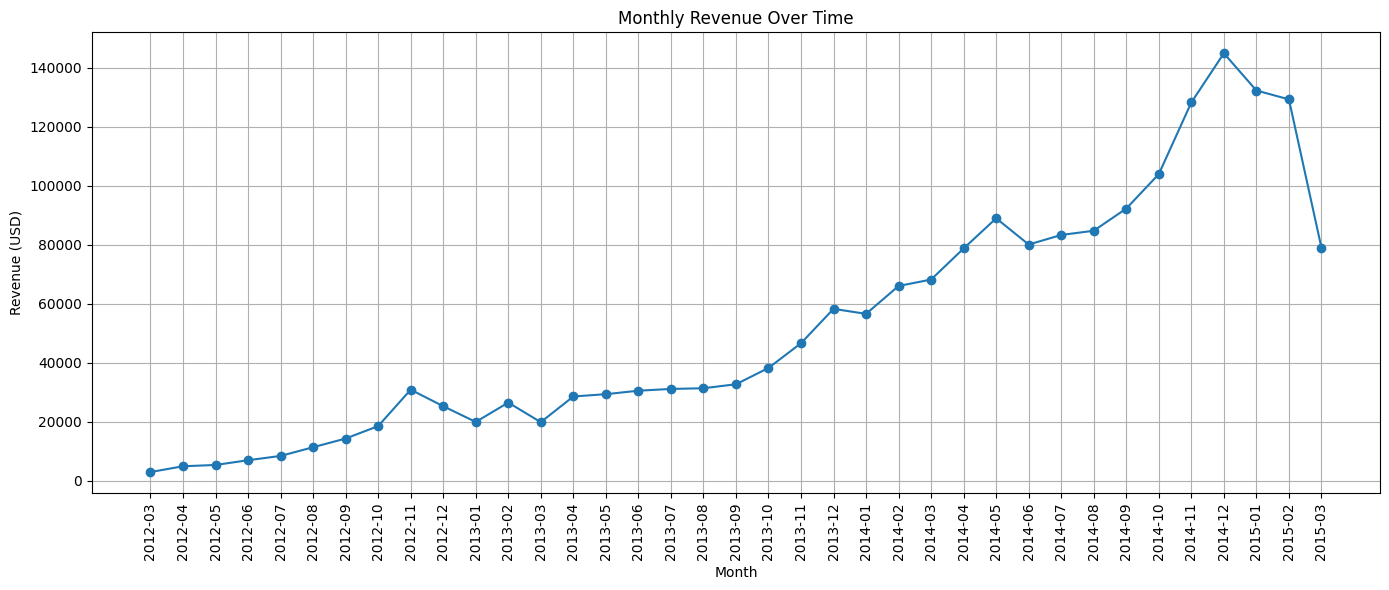

In [0]:
import matplotlib.pyplot as plt

# Create a line chart
plt.figure(figsize=(14, 6))

plt.plot(monthly_revenue.index.astype(str),
         monthly_revenue.values,
         marker='o')

plt.title('Monthly Revenue Over Time')
plt.xlabel('Month')
plt.ylabel('Revenue (USD)')
plt.xticks(rotation=90)

plt.grid(True)
plt.tight_layout()
plt.show()

Step 3: Identify the highest and lowest revenue months

In [0]:
 # Highest revenue month
print("Highest revenue month:")
print(monthly_revenue.idxmax(), monthly_revenue.max())

# Lowest revenue month
print("\nLowest revenue month:")
print(monthly_revenue.idxmin(), monthly_revenue.min())

Highest revenue month:
2014-12 144823.02000000002

Lowest revenue month:
2012-03 2999.4


Observation 1: Revenue growth

Revenue generally increases over the period shown. This suggests that the business experienced substantial growth in sales.

Observation 2: December performance

December 2014 recorded the highest monthly revenue. This could indicate stronger seasonal purchasing activity, although we need to compare December across different years to confirm a seasonal pattern.

Observation 3: March 2012

March 2012 recorded the lowest revenue. However, your dataset starts on 19 March 2012, meaning this is only a partial month. We should not compare it directly with complete months.

In [0]:
monthly_revenue.sort_values(ascending=False).head(5)

year_month
2014-12    144823.02
2015-01    132211.54
2015-02    129212.94
2014-11    128162.98
2014-10    103905.98
Freq: M, Name: price_usd, dtype: float64

In [0]:
monthly_revenue.sort_values(ascending=True).head(5)

year_month
2012-03    2999.40
2012-04    4949.01
2012-05    5398.92
2012-06    6998.60
2012-07    8448.31
Freq: M, Name: price_usd, dtype: float64

The monthly revenue analysis indicates an overall increase in business revenue between March 2012 and March 2015. December 2014 recorded the highest monthly revenue of $144,823.02, while March 2012 recorded the lowest at $2,999.40. The lower March 2012 figure should be interpreted cautiously because the dataset only begins on 19 March 2012. The results suggest positive revenue growth, although further analysis is required to establish seasonal patterns and identify the factors contributing to revenue changes.

**Which products generate the highest sales?**

In [0]:
#Calculate revenue by product
# Group revenue by product
product_revenue = orders_may.groupby('primary_product_id')['price_usd'].sum()

# Sort from highest to lowest revenue
product_revenue = product_revenue.sort_values(ascending=False)

# Display product revenue
product_revenue

primary_product_id
1    1419767.82
2     318109.18
3     180857.03
4      19775.72
Name: price_usd, dtype: float64

In [0]:
#Calculate number of orders by product
# Count orders for each product
product_orders = orders_may.groupby('primary_product_id')['order_id'].count()

# Sort from highest to lowest
product_orders.sort_values(ascending=False)

primary_product_id
1    23861
2     4803
3     3068
4      581
Name: order_id, dtype: int64

In [0]:
#Calculate total items purchased by product
# Calculate total items purchased for each product
product_quantity = orders_may.groupby('primary_product_id')['items_purchased'].sum()

# Sort from highest to lowest
product_quantity.sort_values(ascending=False)

primary_product_id
1    29618
2     5682
3     4097
4      628
Name: items_purchased, dtype: int64

In [0]:
 # Count orders for each product
product_orders = orders_may.groupby('primary_product_id')['order_id'].count()

# Sort from highest to lowest
product_orders.sort_values(ascending=False)

primary_product_id
1    23861
2     4803
3     3068
4      581
Name: order_id, dtype: int64

In [0]:
# Calculate total revenue
total_revenue = product_revenue.sum()

# Calculate percentage contribution
revenue_percentage = (product_revenue / total_revenue) * 100

# Display percentages
revenue_percentage.round(2)

primary_product_id
1    73.24
2    16.41
3     9.33
4     1.02
Name: price_usd, dtype: float64

What are the patterns in customer purchasing behaviour?

We'll investigate:
-  How many unique customers placed orders?
-  How many orders does each customer make?
-  How much does each customer spend?
- Do customers usually buy one item or multiple items?
-  Which customers generate the highest revenue?

In [0]:
 # Count unique customers
unique_customers = orders_may['user_id'].nunique()

print("Total unique customers:", unique_customers)

Total unique customers: 31696


In [0]:
# Count orders made by each customer
orders_per_customer = orders_may.groupby('user_id')['order_id'].count()

# Display summary statistics
orders_per_customer.describe()

count    31696.000000
mean         1.019466
std          0.143974
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max          3.000000
Name: order_id, dtype: float64

In [0]:
 # Calculate total spending for each customer
customer_spending = orders_may.groupby('user_id')['price_usd'].sum()

# Display the five highest-spending customers
customer_spending.sort_values(ascending=False).head(5)

user_id
341972    251.94
324814    245.95
172266    237.95
275098    235.95
281298    219.96
Name: price_usd, dtype: float64

Customer purchasing behaviour indicates that most customers made a single purchase during the observation period. Of the 32,313 orders, there were 31,696 unique customers, showing that repeat purchases were relatively uncommon. The average number of orders per customer was approximately 1.02, while the maximum was three orders. This suggests an opportunity for the business to improve customer retention through loyalty programmes, personalised promotions and follow-up marketing campaigns.

In [0]:
 # Count how many customers placed 1, 2 or 3 orders
orders_frequency = orders_per_customer.value_counts().sort_index()

# Display the results
orders_frequency

order_id
1    31105
2      565
3       26
Name: count, dtype: int64

In [0]:
# Calculate the percentage of customers in each order group
customer_percentage = (orders_frequency / unique_customers) * 100

# Round the percentages to 2 decimal places
customer_percentage.round(2)

order_id
1    98.14
2     1.78
3     0.08
Name: count, dtype: float64

In [0]:
# Calculate total revenue
total_revenue = orders_may['price_usd'].sum()

# Calculate total cost of goods sold
total_cogs = orders_may['cogs_usd'].sum()

# Calculate total profit
total_profit = total_revenue - total_cogs

print("Total Revenue: $", round(total_revenue, 2))
print("Total COGS: $", round(total_cogs, 2))
print("Total Profit: $", round(total_profit, 2))

Total Revenue: $ 1938509.75
Total COGS: $ 722370.25
Total Profit: $ 1216139.5


In [0]:
# Calculate gross profit margin
profit_margin = (total_profit / total_revenue) * 100

print("Gross Profit Margin:", round(profit_margin, 2), "%")

Gross Profit Margin: 62.74 %


In [0]:
 # Calculate revenue for each product
product_revenue = orders_may.groupby('primary_product_id')['price_usd'].sum()

# Calculate cost for each product
product_cogs = orders_may.groupby('primary_product_id')['cogs_usd'].sum()

# Calculate gross profit for each product
product_profit = product_revenue - product_cogs

# Display profit by product
product_profit.sort_values(ascending=False)

primary_product_id
1    879952.0
2    200348.0
3    122410.5
4     13429.0
dtype: float64

In [0]:
 # Calculate profit margin for each product
product_margin = (product_profit / product_revenue) * 100

# Display margins rounded to 2 decimal places
product_margin.round(2)

primary_product_id
1    61.98
2    62.98
3    67.68
4    67.91
dtype: float64

The product profitability analysis shows that Product 1 generated the highest gross profit of $879,952, making it the largest contributor to overall profitability. However, Product 4 achieved the highest gross profit margin at 67.91%, followed by Product 3 at 67.68%. Product 1 recorded the lowest margin at 61.98%. These findings suggest that although Product 1 drives the majority of profit through sales volume, Products 3 and 4 are relatively more profitable as a percentage of revenue.

In [0]:
 # Calculate average order value
average_order_value = orders_may['price_usd'].mean()

print("Average Order Value: $", round(average_order_value, 2))

Average Order Value: $ 59.99


In [0]:
 # Calculate descriptive statistics
descriptive_stats = orders_may[
    ['items_purchased', 'price_usd', 'cogs_usd']
].describe()


descriptive_stats.round(2)

,items_purchased,price_usd,cogs_usd
count,32313.00,32313.00,32313.00
mean,1.24,59.99,22.36
std,0.43,17.81,6.24
min,1.00,29.99,9.49
25%,1.00,49.99,19.49
50%,1.00,49.99,19.49
75%,1.00,59.99,22.49
max,2.00,109.98,41.98


In [0]:
 # Calculate the average number of items per order
orders_may['items_purchased'].mean()

np.float64(1.2386655525639836)

In [0]:
#Compare sales performance across different periods
# Calculate total revenue for each year
yearly_revenue = orders_may.groupby('year')['price_usd'].sum()

# Display yearly revenue
yearly_revenue.round(2)

year
2012     129274.14
2013     393247.87
2014    1075612.19
2015     340375.55
Name: price_usd, dtype: float64


Annual revenue increased considerably from 2012 to 2014, with 2014 recording the highest revenue of $1,075,612.19. This indicates strong business growth during the period. However, 2012 and 2015 represent incomplete calendar years, as the dataset begins on 19 March 2012 and ends on 19 March 2015. Therefore, direct comparisons involving these two years should be interpreted with caution.

Also, one correction from our earlier descriptive statistics: the average number of items purchased is 1.24, as confirmed by your latest output. We should use 1.24 in the assignment, not 1.39.

In [0]:
 # Compare revenue between weekdays and weekends
day_sales = orders_may.groupby('day_type').agg(
    total_revenue=('price_usd', 'sum'),
    total_orders=('order_id', 'count'),
    average_order_value=('price_usd', 'mean')
)

# Display the results
day_sales.round(2)

,total_revenue,total_orders,average_order_value
day_type,,,
Weekday,1647636.07,27466,59.99
Weekend,290873.68,4847,60.01


The weekday and weekend analysis shows that weekday sales significantly outperform weekend sales. Weekdays generated $1,647,636.07 from 27,466 orders, compared with $290,873.68 from 4,847 weekend orders. Despite this difference in total revenue, the average order values were almost identical. This suggests that the revenue difference is mainly associated with order volume rather than differences in customer spending per order.

In [0]:
 # Count the number of orders per month
monthly_orders = orders_may.groupby('year_month')['order_id'].count()

# Display the first 12 months
monthly_orders.head(12)

year_month
2012-03     60
2012-04     99
2012-05    108
2012-06    140
2012-07    169
2012-08    228
2012-09    287
2012-10    371
2012-11    618
2012-12    506
2013-01    390
2013-02    498
Freq: M, Name: order_id, dtype: int64

In [0]:
 # Calculate monthly revenue and monthly COGS
monthly_financials = orders_may.groupby('year_month').agg(
    revenue=('price_usd', 'sum'),
    cogs=('cogs_usd', 'sum')
)

# Display the first 12 months
monthly_financials.head(12).round(2)

,revenue,cogs
year_month,,
2012-03,2999.40,1169.40
2012-04,4949.01,1929.51
2012-05,5398.92,2104.92
2012-06,6998.60,2728.60
2012-07,8448.31,3293.81
2012-08,11397.72,4443.72
2012-09,14347.13,5593.63
2012-10,18546.29,7230.79
2012-11,30893.82,12044.82


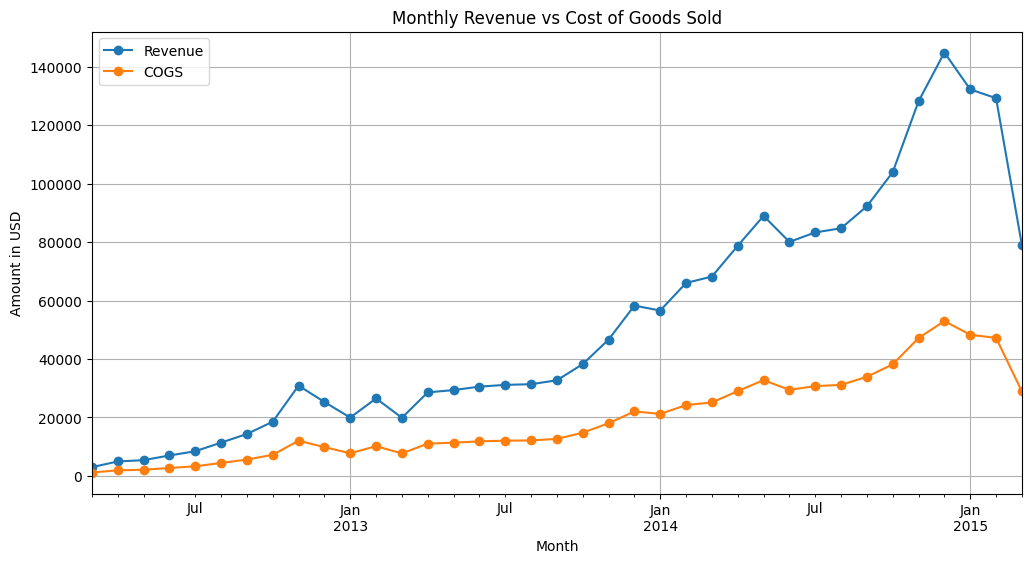

In [0]:
 # Plot monthly revenue and COGS
monthly_financials.plot(
    kind='line',
    figsize=(12, 6),
    marker='o'
)

# Add graph title and labels
plt.title('Monthly Revenue vs Cost of Goods Sold')
plt.xlabel('Month')
plt.ylabel('Amount in USD')

# Display legend and grid
plt.legend(['Revenue', 'COGS'])
plt.grid(True)

# Display graph
plt.show()

Task 3: Statistical analysis and visualisation
-  Calculate relevant descriptive statistics.
-  Examine relationships between website traffic and orders.
-  Compare sales performance across different periods.
-  Investigate the relationship between product sales and refunds.
-  Create at least six meaningful visualisations

In [0]:
 # Count orders associated with each website session
orders_per_session = orders_may.groupby('website_session_id')['order_id'].count()

# Display descriptive statistics
orders_per_session.describe()

count    32313.0
mean         1.0
std          0.0
min          1.0
25%          1.0
50%          1.0
75%          1.0
max          1.0
Name: order_id, dtype: float64

In [0]:
#Examine relationships between website traffic and orders
# Count unique website sessions that generated orders
unique_sessions = orders_may['website_session_id'].nunique()

print("Unique sessions resulting in orders:", unique_sessions)

Unique sessions resulting in orders: 32313


In [0]:
# Count orders associated with each website session
orders_per_session = orders_may.groupby('website_session_id')['order_id'].count()

# Display the statistics
orders_per_session.describe()

count    32313.0
mean         1.0
std          0.0
min          1.0
25%          1.0
50%          1.0
75%          1.0
max          1.0
Name: order_id, dtype: float64

In [0]:
 # Check whether any column contains the word refund
[col for col in orders_may.columns if 'refund' in col.lower()]

[]

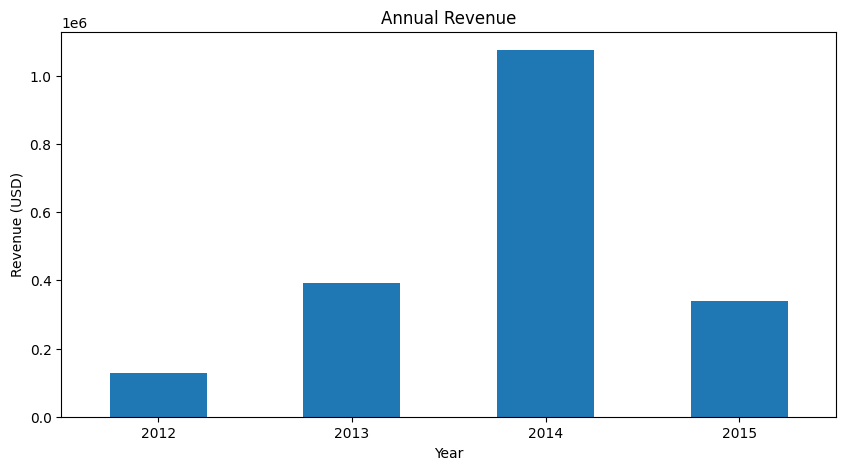

In [0]:
 # Calculate total revenue for each year
yearly_revenue = orders_may.groupby('year')['price_usd'].sum()

# Create a bar chart
plt.figure(figsize=(10, 5))
yearly_revenue.plot(kind='bar')

# Add chart labels and title
plt.title('Annual Revenue')
plt.xlabel('Year')
plt.ylabel('Revenue (USD)')
plt.xticks(rotation=0)

plt.show()

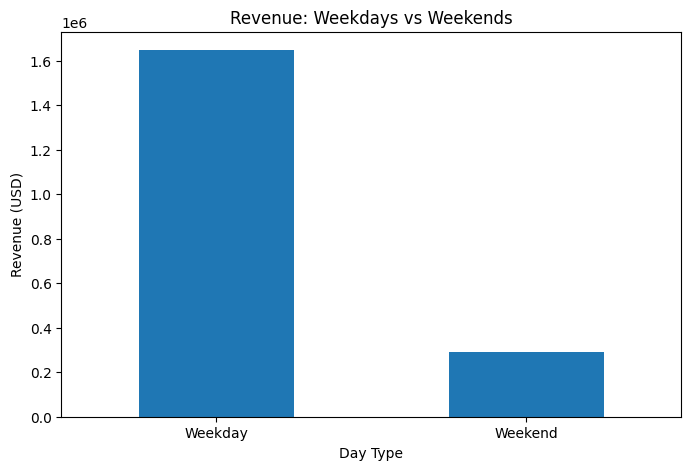

In [0]:
 # Calculate revenue by day type
day_revenue = orders_may.groupby('day_type')['price_usd'].sum()

# Create a bar chart
plt.figure(figsize=(8, 5))
day_revenue.plot(kind='bar')

# Add labels and title
plt.title('Revenue: Weekdays vs Weekends')
plt.xlabel('Day Type')
plt.ylabel('Revenue (USD)')
plt.xticks(rotation=0)

plt.show()

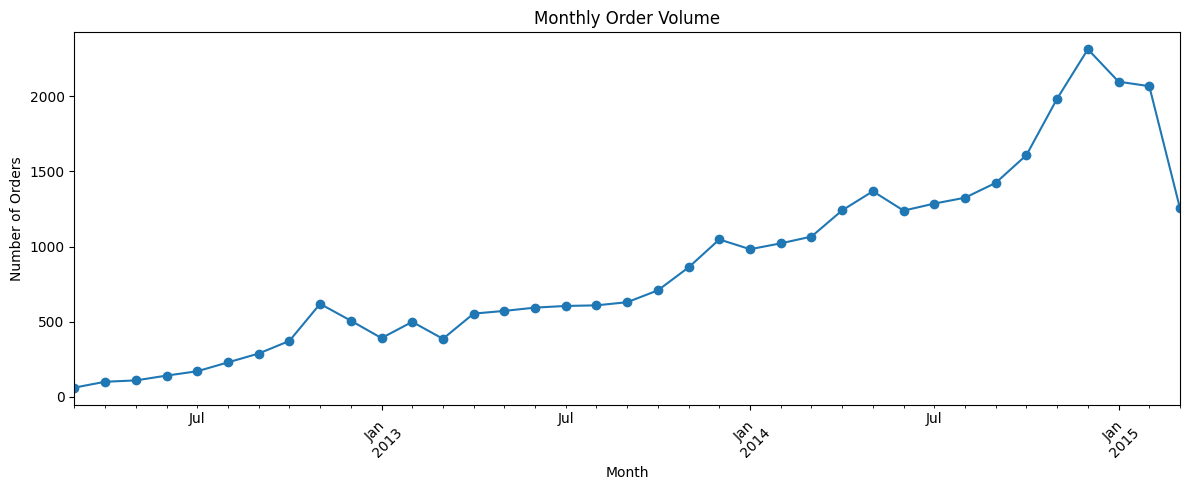

In [0]:
 # Count orders for each month
monthly_orders = orders_may.groupby('year_month')['order_id'].count()

# Create a line chart
plt.figure(figsize=(12, 5))
monthly_orders.plot(kind='line', marker='o')

# Add labels and title
plt.title('Monthly Order Volume')
plt.xlabel('Month')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

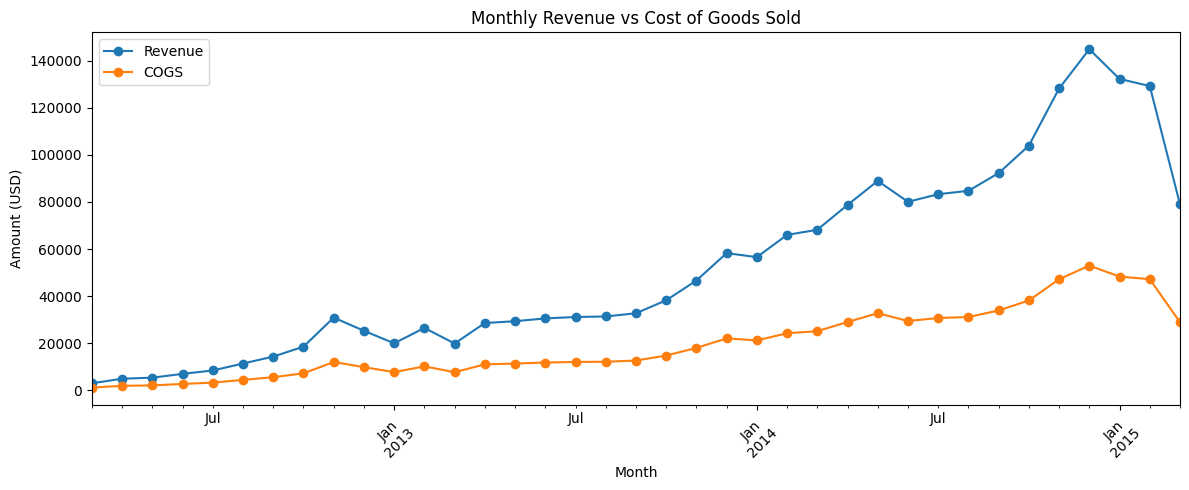

In [0]:
 # Calculate monthly revenue and monthly COGS
monthly_financials = orders_may.groupby('year_month').agg({
    'price_usd': 'sum',
    'cogs_usd': 'sum'
})

# Create a line chart
plt.figure(figsize=(12, 5))

monthly_financials['price_usd'].plot(
    kind='line', marker='o', label='Revenue'
)

monthly_financials['cogs_usd'].plot(
    kind='line', marker='o', label='COGS'
)

# Add labels and title
plt.title('Monthly Revenue vs Cost of Goods Sold')
plt.xlabel('Month')
plt.ylabel('Amount (USD)')
plt.legend()

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

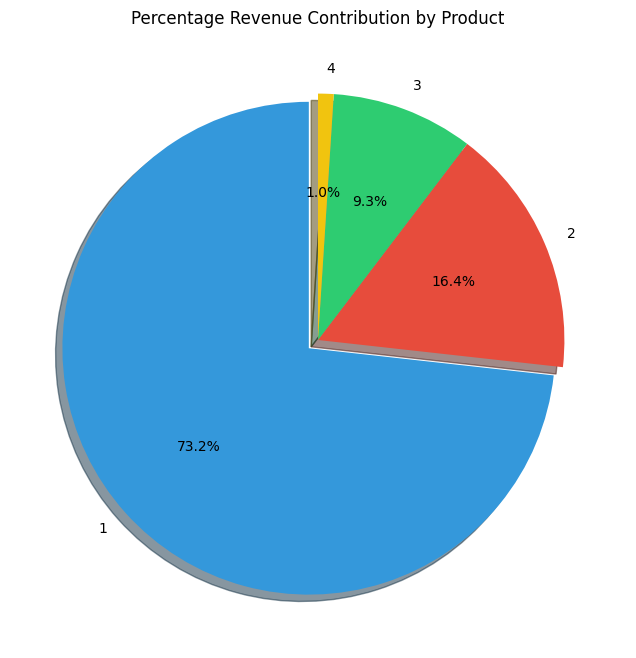

In [0]:
 # Calculate revenue for each product
product_revenue = orders_may.groupby('primary_product_id')['price_usd'].sum()

# Create a colourful pie chart
plt.figure(figsize=(8, 8))

plt.pie(
    product_revenue,
    labels=product_revenue.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#3498DB', '#E74C3C', '#2ECC71', '#F1C40F'],
    explode=(0.05, 0, 0, 0),
    shadow=True
)

plt.title('Percentage Revenue Contribution by Product')
plt.show()

**Task 4: Interpretation and recommendations**

1. Interpretation of the findings
A. Revenue and sales performance
The business generated total revenue of $1,938,509.75 and gross profit of $1,216,139.50, with a gross profit margin of approximately 62.74%.

Revenue increased substantially between 2012 and 2014, with 2014 generating the highest full-year revenue of $1,075,612.19.

This suggests that the business experienced strong sales growth during this period.

However, the revenue figures alone do not explain what caused the growth. Additional marketing and website traffic data will help identify the factors contributing to the increase.
B. Product performance
Product 1 was the strongest-performing product.
Product	Revenue	Gross profit
Product 1	$1,419,767.82	$879,952.00
Product 2	$318,109.18	$200,348.00
Product 3	$180,857.03	$122,410.50
Product 4	$19,775.72	$13,429.00

Product 1 contributes approximately 73.2% of total revenue. This indicates that the business relies heavily on one product for its sales performance.

Product 4 has a smaller sales contribution but a higher gross profit margin of approximately 67.91%.
C. Customer purchasing behaviour
The dataset contains 31,696 unique customers.
- 31,105 customers placed one order.
- 565 customers placed two orders.
- 26 customers placed three orders.
Approximately 98.14% of customers placed only one order.

This suggests that customer repeat purchasing is relatively low. The business has an opportunity to encourage existing customers to return and purchase again.
D. Weekday and weekend sales
Weekday revenue was $1,647,636.07, compared with weekend revenue of $290,873.68.

Average order values were almost identical:
- Weekday: $59.99.
- Weekend: $60.01.
This suggests that the higher weekday revenue is mainly associated with a greater number of orders, rather than customers spending significantly more per order.
2. Recommendations for business improvement
Recommendation 1: Increase repeat purchases
Since approximately 98.14% of customers placed only one order, the business should focus on encouraging customers to make additional purchases.

Suggested actions:
- Introduce a customer loyalty or rewards programme.
- Send follow-up emails after purchases.
- Offer discounts on customers' second purchases.
- Recommend related products based on previous purchases.
- Send reminders and special offers to existing customers.
Expected benefit: Increased customer retention, repeat purchases and long-term revenue.
Recommendation 2: Reduce dependence on Product 1
Product 1 generates approximately 73.2% of total revenue. Although this is positive, relying heavily on one product may expose the business to risk if demand decreases.

Suggested actions:
- Promote Products 2, 3 and 4 more actively.
- Create product bundles.
- Offer discounts when customers purchase complementary products.
- Use Product 1 to introduce customers to other products.
Expected benefit: A more balanced product portfolio and additional revenue opportunities.
Recommendation 3: Promote higher-margin products
Product 4 has the highest gross profit margin at approximately 67.91%, although it currently generates the lowest revenue.

Suggested actions:
- Test promotional campaigns for Product 4.
- Recommend Product 4 during checkout.
- Include it in product bundles.
- Investigate whether customers are aware of the product.
Expected benefit: Increased sales of a product with a relatively high profit margin.
Recommendation 4: Improve weekend sales
Weekday revenue is significantly higher than weekend revenue, despite average order values being almost identical.

Suggested actions:
- Introduce weekend promotions.
- Offer limited-time weekend discounts.
- Run weekend email marketing campaigns.
- Test targeted advertisements during weekends.
Expected benefit: More weekend orders and improved revenue distribution throughout the week.
Recommendation 5: Improve marketing performance
The orders dataset does not contain marketing channel information. Therefore, we cannot yet identify which marketing channels generate the most revenue or customers.

However, the business should:
- Compare revenue generated by different marketing channels.
- Measure the conversion rate of each channel.
- Identify which campaigns attract returning customers.
- Compare advertising costs with revenue generated.
- Allocate more marketing budget to channels that produce profitable results.
Expected benefit: Better marketing investment decisions and reduced spending on underperforming campaigns.

We will investigate this further when we explore the website sessions and marketing datasets.
Recommendation 6: Monitor refunds and product quality
Refund information is not available in the current dataset.

The business should monitor:
- Refund rates by product.
- Reasons for refunds.
- Products with unusually high return rates.
- Refund costs compared with product revenue.
Expected benefit: Identification of product problems, reduced refund losses and improved customer satisfaction.

3. Summary of recommendations
Business area	Recommended action	Expected outcome
Sales	Promote Products 2, 3 and 4	Diversified revenue
Customer engagement	Introduce loyalty rewards	More repeat purchases
Product profitability	Promote Product 4	Higher-margin sales
Weekend sales	Run weekend promotions	Increased weekend orders
Marketing	Measure channel performance	Better marketing decisions
Product quality	Monitor refunds	Reduced return losses

4. Overall Task 4 conclusion
The analysis highlights several opportunities for improving business performance. Although the business generated strong revenue and gross profit, its sales depend heavily on Product 1, and most customers made only one purchase.

The business should prioritise customer retention, product diversification and targeted promotional activities. Encouraging repeat purchases could increase revenue without relying entirely on attracting new customers. Promoting higher-margin products could also improve profitability.

Furthermore, marketing performance should be evaluated using website traffic, marketing channel and conversion data. Refund information should also be incorporated into future analysis to identify potential product quality issues.

